In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures

df = pd.read_csv("../dataset/Salary_Data.csv")
X = df[["Employee_ID", "Department"]]
y = df["Monthly_Salary_INR"].values
df.head(10)

,Employee_ID,Employee_Name,Department,Monthly_Salary_INR
0,1,Vihaan Sharma,Operations,58048
1,2,Krishna Singh,HR,118530
2,3,Vihaan Nair,IT,99397
3,4,Myra Sharma,IT,34280
4,5,Reyansh Singh,Marketing,100907
5,6,Aarav Nair,HR,115850
6,7,Kavya Das,HR,80878
7,8,Riya Kumar,IT,42926
8,9,Myra Gupta,Finance,42379
9,10,Reyansh Gupta,IT,34156


In [12]:
def make_pipeline(degree=None):
    feature_step = (
        "passthrough"
        if degree is None
        else Pipeline([("poly", PolynomialFeatures(degree=degree, include_bias=False))])
    )
    preprocessor = ColumnTransformer([
        ("id_feat", feature_step, ["Employee_ID"]),
        ("dept", OneHotEncoder(drop="first", handle_unknown="ignore"), ["Department"]),
    ])
    return Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression()),
    ])

lin_model = make_pipeline(degree=None).fit(X, y)
poly4_model = make_pipeline(degree=4).fit(X, y)

print(f"Linear + Dept R²: {r2_score(y, lin_model.predict(X)):.4f}")
print(f"Polynomial (Deg 4) + Dept R²: {r2_score(y, poly4_model.predict(X)):.4f}")

Linear + Dept R²: 0.0376
Polynomial (Deg 4) + Dept R²: 0.0276


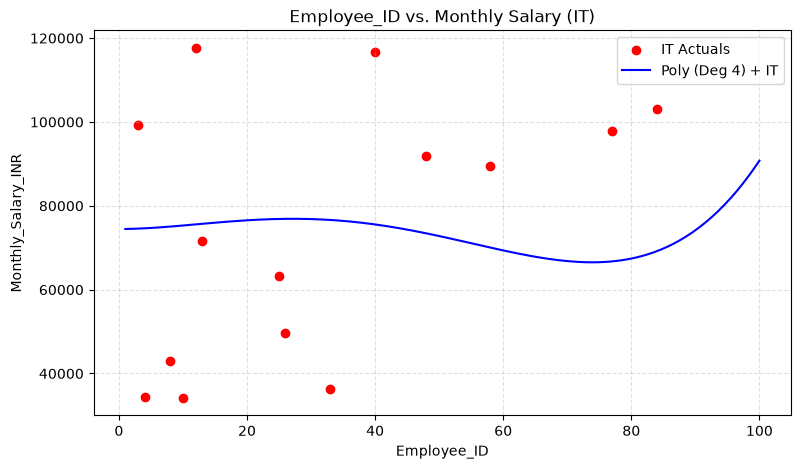

In [13]:
dept = "IT"
id_grid = np.linspace(df["Employee_ID"].min(), df["Employee_ID"].max(), 200)
grid_df = pd.DataFrame({"Employee_ID": id_grid, "Department": [dept] * len(id_grid)})
dept_rows = df[df["Department"] == dept]

plt.figure(figsize=(9, 5))
plt.scatter(dept_rows["Employee_ID"], dept_rows["Monthly_Salary_INR"], color="red", label=f"{dept} Actuals")
plt.plot(id_grid, poly4_model.predict(grid_df), color="blue", label=f"Poly (Deg 4) + {dept}")
plt.title(f"Employee_ID vs. Monthly Salary ({dept})")
plt.xlabel("Employee_ID")
plt.ylabel("Monthly_Salary_INR")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()